# Smart Customer Segmentation – sklearn Pipeline version

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from kneed import KneeLocator

In [2]:
df = pd.read_csv("smartcart_customers.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


## 1. Row-level cleaning (outliers)
Removing rows cannot be done inside a sklearn Pipeline, so this is the only step kept outside.

In [3]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

# keep rows with missing Income (they get imputed inside the pipeline)
df = df[(df["Income"].isna()) | (df["Income"] < 600000)]
df = df[(2026 - df["Year_Birth"]) < 100]
df.shape

(2236, 22)

## 2. Feature engineering (as a pipeline step)

In [4]:
EDU_MAP = {
    "Graduation": "Graduation",
    "PhD": "Postgraduation",
    "Masters": "Postgraduation",
    "2n Cycle": "Undergraduation",
    "Basic": "Undergraduation",
}
LIVING_MAP = {
    "Together": "Partner", "Married": "Partner",
    "Single": "Alone", "Divorced": "Alone", "Widow": "Alone",
    "Alone": "Alone", "Absurd": "Alone", "YOLO": "Alone",
}
SPEND_COLS = ["MntWines", "MntFruits", "MntMeatProducts",
              "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
DROP_COLS = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome",
             "Dt_Customer"] + SPEND_COLS

def engineer_features(data):
    data = data.copy()
    data["Age"] = 2026 - data["Year_Birth"]
    data["CustomerTenureDays"] = (data["Dt_Customer"].max() - data["Dt_Customer"]).dt.days
    data["TotalSpending"] = data[SPEND_COLS].sum(axis=1)
    data["TotalChildren"] = data["Kidhome"] + data["Teenhome"]
    data["Education"] = data["Education"].replace(EDU_MAP)
    data["LivingWith"] = data["Marital_Status"].replace(LIVING_MAP)
    return data.drop(columns=DROP_COLS)

feature_engineering = FunctionTransformer(engineer_features)

## 3. Preprocessing: impute, one-hot encode, scale

In [5]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(sparse_output=False)),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, make_column_selector(dtype_include=np.number)),
    ("cat", categorical_pipe, make_column_selector(dtype_exclude=np.number)),
])

## 4. Full pipeline

In [6]:
# first, a pipeline WITHOUT the clustering step, used to explore the best K
prep_pipeline = Pipeline([
    ("features", feature_engineering),
    ("preprocess", preprocessor),
])

X_scaled = prep_pipeline.fit_transform(df)
X_scaled.shape

(2236, 19)

## 5. PCA for visualisation + choosing K

[0.21946114 0.10788244 0.09588632]


Text(0.5, 0, 'PCA3')

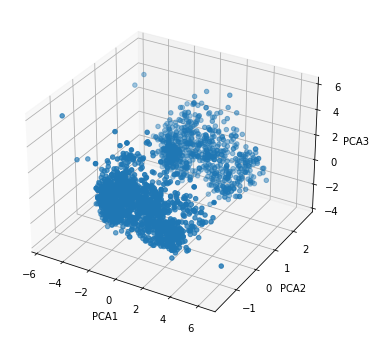

In [7]:
pca = PCA(n_components=3)
X_PCA = pca.fit_transform(X_scaled)
print(pca.explained_variance_ratio_)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_PCA[:, 0], X_PCA[:, 1], X_PCA[:, 2])
ax.set_xlabel("PCA1"); ax.set_ylabel("PCA2"); ax.set_zlabel("PCA3")

Elbow K: 4


Text(0, 0.5, 'Silhouette score')

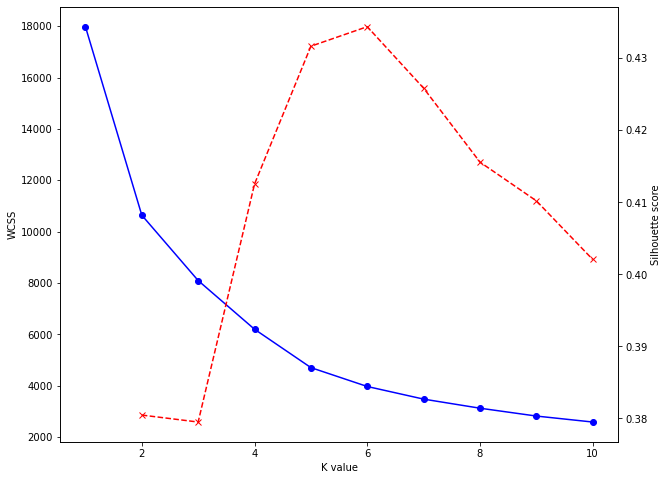

In [8]:
wcss, scores = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_PCA)
    wcss.append(km.inertia_)
    if k >= 2:
        scores.append(silhouette_score(X_PCA, km.labels_))

print("Elbow K:", KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing").elbow)

fig, ax1 = plt.subplots(figsize=(10, 8))
ax1.plot(range(1, 11), wcss, marker="o", color="blue")
ax1.set_xlabel("K value"); ax1.set_ylabel("WCSS")
ax2 = ax1.twinx()
ax2.plot(range(2, 11), scores, marker="x", color="red", linestyle="--")
ax2.set_ylabel("Silhouette score")

## 6. Final end-to-end pipeline (raw data in, cluster labels out)

In [9]:
segmentation_pipeline = Pipeline([
    ("features", feature_engineering),
    ("preprocess", preprocessor),
    ("kmeans", KMeans(n_clusters=4, random_state=42, n_init=10)),
])

labels = segmentation_pipeline.fit_predict(df)
df["Cluster"] = labels
df["Cluster"].value_counts().sort_index()

0    674
1    554
2    464
3    544
Name: Cluster, dtype: int64

## 7. KMeans vs Agglomerative (side by side)

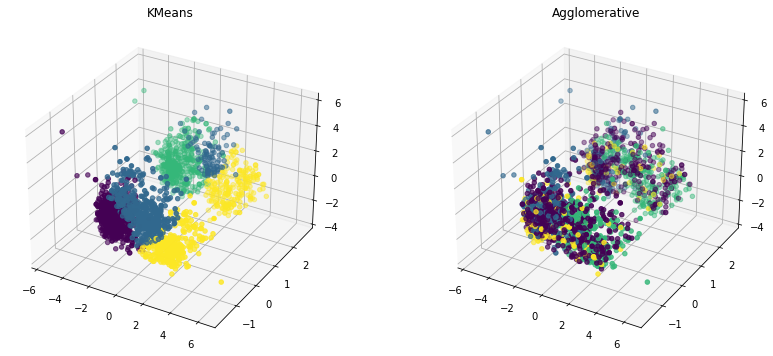

In [10]:
labels_agglo = AgglomerativeClustering(n_clusters=4).fit_predict(X_scaled)

fig = plt.figure(figsize=(14, 6))
for i, (lab, title) in enumerate([(labels, "KMeans"), (labels_agglo, "Agglomerative")], 1):
    ax = fig.add_subplot(1, 2, i, projection="3d")
    ax.scatter(X_PCA[:, 0], X_PCA[:, 1], X_PCA[:, 2], c=lab)
    ax.set_title(title)

## 8. Cluster profiling

In [11]:
profile = segmentation_pipeline.named_steps["features"].transform(df.drop(columns="Cluster"))
profile["Cluster"] = labels
profile.groupby("Cluster").mean(numeric_only=True)

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,CustomerTenureDays,TotalSpending,TotalChildren
Cluster,,,,,,,,,,,,,
0,34624.400901,49.338279,1.918398,2.105341,0.548961,3.280415,6.396142,0.010386,0.062315,54.652819,319.247774,101.781899,1.209199
1,59366.007286,49.357401,3.922383,6.815884,3.337545,8.054152,5.787004,0.009025,0.111913,60.633574,430.487365,826.610108,1.187726
2,38266.425439,47.532328,2.407328,2.823276,0.915948,3.851293,6.424569,0.010776,0.137931,55.642241,339.890086,189.226293,1.228448
3,77322.754159,49.946691,1.136029,4.843750,6.086397,8.270221,2.564338,0.005515,0.305147,57.784926,330.266544,1361.474265,0.152574


<AxesSubplot:xlabel='Cluster', ylabel='count'>

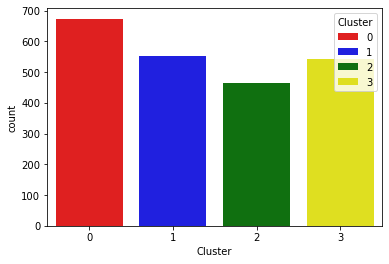

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df["Cluster"], hue=df["Cluster"], palette=["red", "blue", "green", "yellow"])

In [ ]:
# New customers can now be segmented straight from raw data:
# segmentation_pipeline.predict(new_customers_df)